In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
sys.path.append("..")

import ast
import json
from pathlib import Path
import numpy as np
import xarray as xr
import rioxarray as rxr
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid", {"grid.color": ".93"})

from src.load_data import ClimateModelData
from src.timesteps_adjustments import extract_adjusted_timesteps, get_new_timesteps

In [98]:
paths = json.load(open("../paths.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_figs = Path(paths["path_figs"])

# Load climate model data

In [5]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

institute = climate_model_chain.split("-")[0]
rcm = climate_model_chain.split("_")[0]
gcm = climate_model_chain.split("_")[1]
ensemble = climate_model_chain.split("_")[-1]

In [93]:
wind_vars = ["ua100m", "va100m", "ua150m", "va150m", "ua200m", "va200m"]
for var in wind_vars:
    (Path("/landclim/yhaddad/cordex/EUR-11") / climate_scenario / temp_res / var / institute / gcm / rcm / ensemble).mkdir(parents=True, exist_ok=True)
    (Path("/landclim/yhaddad/cordex/EUR-11") / "historical" / temp_res / var / institute / gcm / rcm / ensemble).mkdir(parents=True, exist_ok=True)

## 1. Load linearized mapping of years to adjust warming trend of EURO-CORDEX model

In [6]:
df_climate_models_mapping = pd.read_csv(path_data_adjusted_cordex / "year_lists.csv")
df_climate_models_mapping["year_list"] = [ast.literal_eval(l) for l in df_climate_models_mapping["year_list"]]

adjusted_timesteps = extract_adjusted_timesteps(df_climate_models_mapping, climate_model_chain, climate_scenario)

## 2. Load climate data

In [81]:
variable = "tas"
temp_res = "3hr"

cordex_var = path_data_cordex / climate_scenario / temp_res / variable / institute / gcm / rcm / ensemble
cordex_var_hist = path_data_cordex / "historical" / temp_res / variable / institute / gcm / rcm / ensemble
cordex_processed_var = path_data_processed / "cordex-processed" / f"{climate_model_chain}_{climate_scenario}" / "raw" / f"{variable}_ch.nc"

In [82]:
climate_data = ClimateModelData(cordex_processed_var, chunks=None, load=True)

In [83]:
climate_data.ds_data

<xarray.Dataset> Size: 1GB
Dimensions:  (time: 318496, y: 28, x: 31)
Coordinates:
    height   (time) float64 3MB 2.0 2.0 2.0 2.0 2.0 ... 10.0 10.0 10.0 10.0 10.0
  * time     (time) datetime64[ns] 3MB 1991-01-01 ... 2099-12-31T21:00:00
    lon      (y, x) float64 7kB 5.909 6.067 6.225 6.383 ... 10.33 10.5 10.67
    lat      (y, x) float64 7kB 44.91 44.92 44.92 44.93 ... 48.04 48.04 48.04
  * x        (x) float64 248B 2.462e+03 2.475e+03 ... 2.825e+03 2.838e+03
  * y        (y) float64 224B 2.325e+03 2.338e+03 ... 2.65e+03 2.662e+03
Data variables:
    tas      (time, y, x) float32 1GB nan nan nan nan nan ... nan nan nan nan
Attributes: (12/26)
    description:                    Created by xios
    title:                          Created by xios
    Conventions:                    CF-1.6
    creation_date:                  2018-10-19T08:40:28Z
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...
    name:                           EUR-11_CNRM-CERFACS-CNRM-CM5_historical_r...
    ...                             ...
    CORDEX_domain:                  EUR-11
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    comment:                        CORDEX Europe EUR-11 CNRM-ALADIN 6.3 L91 ...
    c3s_disclaimer:                 This data has been produced in the contex...
    driving_experiment_comment:     Known issue correction: this simulation (...
    frequency:                      3hr

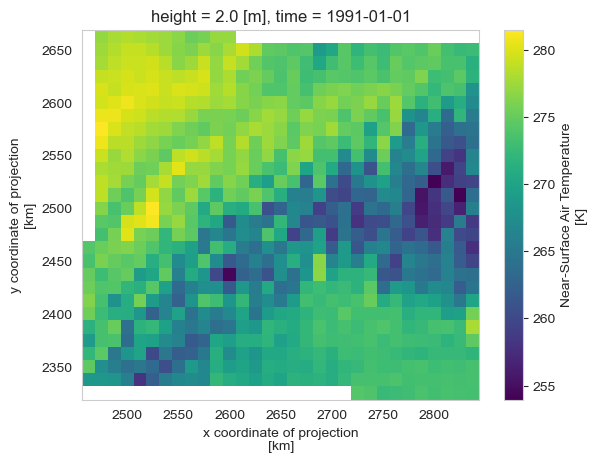

In [84]:
climate_data.ds_data.isel(time=0)[variable].plot()

In [85]:
variables = ["tas", "pr", "rsds", "sfcWind", "huss"]
climate_data_dict = {}

for variable in variables:
    cordex_processed_var = path_data_processed / "cordex-processed" / f"{climate_model_chain}_{climate_scenario}" / "raw" / f"{variable}_ch.nc"
    climate_data_dict[variable] = ClimateModelData(cordex_processed_var, chunks=None, load=True)

## 3. Plot general plots

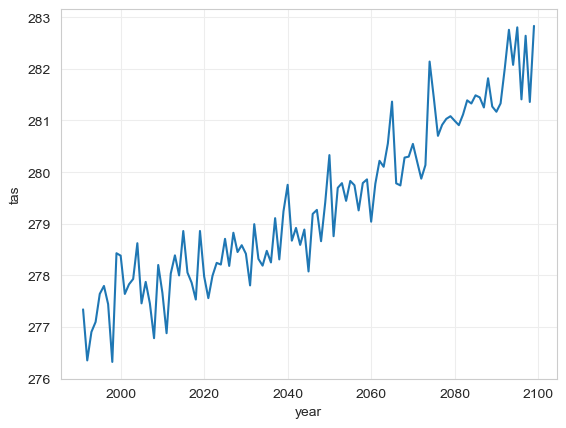

In [88]:
climate_data.plot_annual_mean("tas", spatial_mean=True)

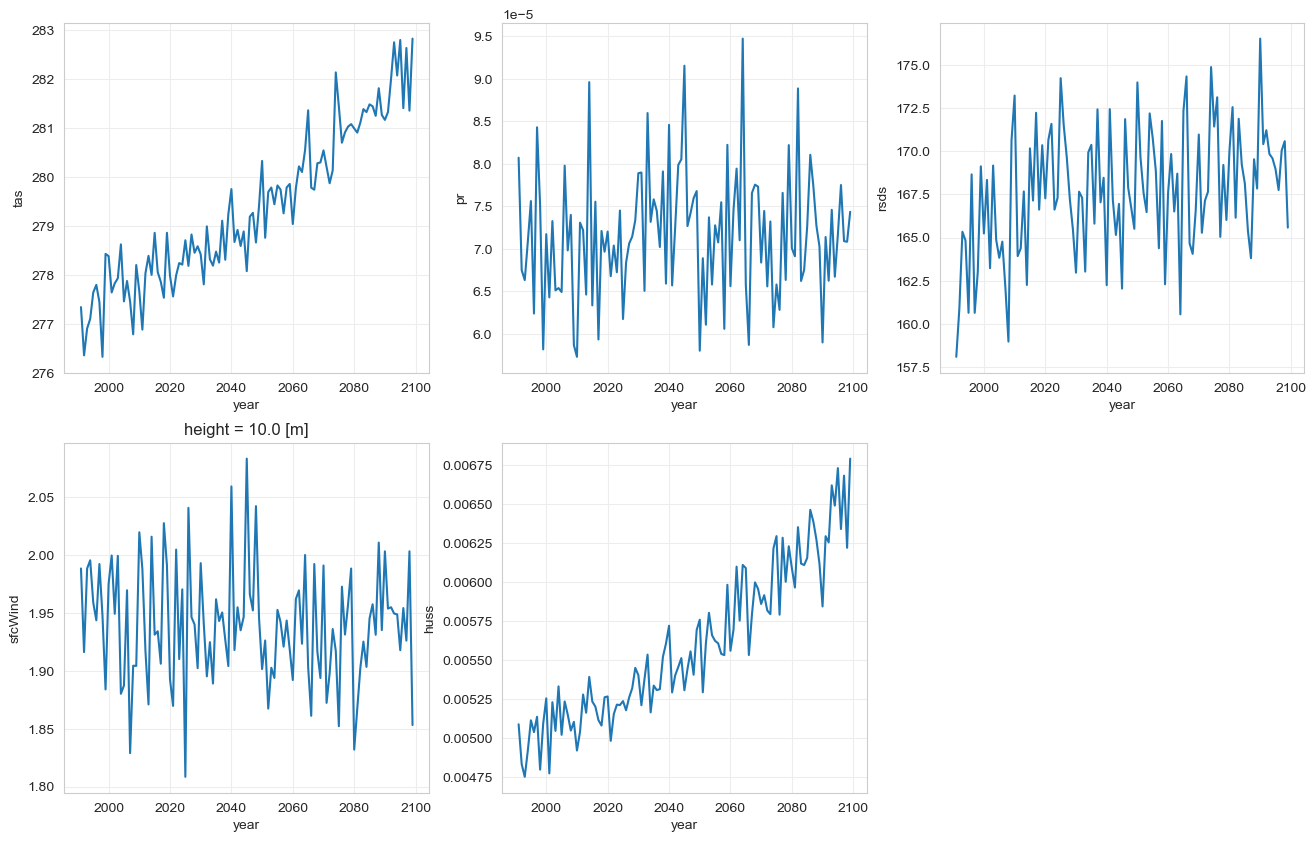

In [91]:
fig, ax = plt.subplots(2, 3, figsize=(16, 10))
ax = ax.flatten()
for i, variable in enumerate(climate_data_dict):
    climate_data_dict[variable].plot_annual_mean(variable, spatial_mean=True, ax=ax[i])

ax[-1].axis("off")
plt.show()